In [70]:
import pandas as pd
import numpy as np

# ML Libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

In [3]:
from datasets import load_dataset

ds = load_dataset("electricsheepafrica/nigerian-banking-retail-transactions")
print(ds)

split_name = next(iter(ds))
table = ds[split_name]
print(table.features)
print(table[:3])

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
'[Errno 8] nodename nor servname provided, or not known' thrown while requesting HEAD https://huggingface.co/datasets/electricsheepafrica/nigerian-banking-retail-transactions/resolve/c31e7981f3a935fc9142923fd082143a4204b4f9/nigerian-banking-retail-transactions.py
Retrying in 1s [Retry 1/5].
'[Errno 8] nodename nor servname provided, or not known' thrown while requesting HEAD https://huggingface.co/datasets/electricsheepafrica/nigerian-banking-retail-transactions/resolve/c31e7981f3a935fc9142923fd082143a4204b4f9/nigerian-banking-retail-transactions.py
Retrying in 2s [Retry 2/5].
'[Errno 8] nodename nor servname provided, or not known' thrown while requesting HEAD https://huggingface.co/datasets/electricsheepafrica/nigerian-banking-retail-tran

DatasetDict({
    train: Dataset({
        features: ['transaction_id', 'account_id', 'customer_id', 'timestamp', 'amount_ngn', 'balance_before_ngn', 'balance_after_ngn', 'transaction_type', 'channel', 'merchant_category_code', 'merchant_name', 'location_lga', 'location_state', 'device_id', 'status', 'fraud_flag'],
        num_rows: 5000000
    })
})
{'transaction_id': Value('string'), 'account_id': Value('string'), 'customer_id': Value('string'), 'timestamp': Value('timestamp[ns]'), 'amount_ngn': Value('float64'), 'balance_before_ngn': Value('float64'), 'balance_after_ngn': Value('float64'), 'transaction_type': Value('string'), 'channel': Value('string'), 'merchant_category_code': Value('string'), 'merchant_name': Value('string'), 'location_lga': Value('string'), 'location_state': Value('string'), 'device_id': Value('string'), 'status': Value('string'), 'fraud_flag': Value('bool')}
{'transaction_id': ['42ae7cb0-052b-4c28-a149-8d7d2cc558a1', 'ce38456c-5bbb-4a83-992a-09e8fd59b49a', '9e6

In [4]:
from datasets import Dataset

first_split = ds[next(iter(ds))]
if isinstance(first_split, Dataset):
    df = first_split.to_pandas()
    print(df.head())

                         transaction_id    account_id   customer_id  \
0  42ae7cb0-052b-4c28-a149-8d7d2cc558a1  ACC-00000334  CUS-00000334   
1  ce38456c-5bbb-4a83-992a-09e8fd59b49a  ACC-00004849  CUS-00004849   
2  9e69c19c-93c8-48fc-b2b8-e89d83b40936  ACC-00082189  CUS-00082189   
3  eb707378-ac9a-4dd6-9a04-9cfe06970123  ACC-00010867  CUS-00010867   
4  b29c3f2e-9712-4d9f-ab0e-32dc91493f3e  ACC-00004080  CUS-00004080   

            timestamp  amount_ngn  balance_before_ngn  balance_after_ngn  \
0 2024-09-14 14:59:00      2100.0       248561.187746      246461.187746   
1 2024-12-26 01:54:00     73400.0       224711.795501      151311.795501   
2 2024-06-15 13:08:00     22600.0       114278.718868      136878.718868   
3 2023-11-18 18:45:00     45900.0       272525.157062      226625.157062   
4 2024-04-21 22:48:00     80000.0       169907.403695       89907.403695   

  transaction_type channel merchant_category_code      merchant_name  \
0            debit     web                  

In [5]:
df.head(5)

,transaction_id,account_id,customer_id,timestamp,amount_ngn,balance_before_ngn,balance_after_ngn,transaction_type,channel,merchant_category_code,merchant_name,location_lga,location_state,device_id,status,fraud_flag
0,42ae7cb0-052b-4c28-a149-8d7d2cc558a1,ACC-00000334,CUS-00000334,2024-09-14 14:59:00,2100.0,248561.187746,246461.187746,debit,web,4814,Airtel,Lagos LGA,Lagos,DEV-5b4184adc38945c2,failed,False
1,ce38456c-5bbb-4a83-992a-09e8fd59b49a,ACC-00004849,CUS-00004849,2024-12-26 01:54:00,73400.0,224711.795501,151311.795501,debit,web,5411,Grand Square,Benue LGA,Benue,DEV-b2b4b029db434254,success,False
2,9e69c19c-93c8-48fc-b2b8-e89d83b40936,ACC-00082189,CUS-00082189,2024-06-15 13:08:00,22600.0,114278.718868,136878.718868,credit,pos,7523,MegaPlaza Parking,Borno LGA,Borno,,success,False
3,eb707378-ac9a-4dd6-9a04-9cfe06970123,ACC-00010867,CUS-00010867,2023-11-18 18:45:00,45900.0,272525.157062,226625.157062,debit,mobile,,,Lagos LGA,Lagos,DEV-5f6ebeaeae504cdd,success,False
4,b29c3f2e-9712-4d9f-ab0e-32dc91493f3e,ACC-00004080,CUS-00004080,2024-04-21 22:48:00,80000.0,169907.403695,89907.403695,debit,branch,,,Lagos LGA,Lagos,,failed,False


In [6]:
df.shape

(5000000, 16)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000000 entries, 0 to 4999999
Data columns (total 16 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   transaction_id          str           
 1   account_id              str           
 2   customer_id             str           
 3   timestamp               datetime64[ns]
 4   amount_ngn              float64       
 5   balance_before_ngn      float64       
 6   balance_after_ngn       float64       
 7   transaction_type        str           
 8   channel                 str           
 9   merchant_category_code  str           
 10  merchant_name           str           
 11  location_lga            str           
 12  location_state          str           
 13  device_id               str           
 14  status                  str           
 15  fraud_flag              bool          
dtypes: bool(1), datetime64[ns](1), float64(3), str(11)
memory usage: 1.1 GB


In [8]:
# Downcast floating-point columns from float64 to float32
float_cols = ["amount_ngn", "balance_before_ngn", "balance_after_ngn"]
df[float_cols] = df[float_cols].astype("float32")

categorical_cols = [
    "transaction_type",
    "channel",
    "merchant_category_code",
    "location_state",
    "status",
]
for col in categorical_cols:
    df[col] = df[col].astype("category")
    
id_cols = [
    "transaction_id",
    "account_id",
    "customer_id",
    "merchant_name",
    "location_lga",
    "device_id",
]
for col in id_cols:
    df[col] = df[col].astype("string")

print(df.info(memory_usage="deep"))

<class 'pandas.DataFrame'>
RangeIndex: 5000000 entries, 0 to 4999999
Data columns (total 16 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   transaction_id          string        
 1   account_id              string        
 2   customer_id             string        
 3   timestamp               datetime64[ns]
 4   amount_ngn              float32       
 5   balance_before_ngn      float32       
 6   balance_after_ngn       float32       
 7   transaction_type        category      
 8   channel                 category      
 9   merchant_category_code  category      
 10  merchant_name           string        
 11  location_lga            string        
 12  location_state          category      
 13  device_id               string        
 14  status                  category      
 15  fraud_flag              bool          
dtypes: bool(1), category(5), datetime64[ns](1), float32(3), string(6)
memory usage: 741.5 MB
None


In [9]:
df.isnull().sum()

transaction_id            0
account_id                0
customer_id               0
timestamp                 0
amount_ngn                0
balance_before_ngn        0
balance_after_ngn         0
transaction_type          0
channel                   0
merchant_category_code    0
merchant_name             0
location_lga              0
location_state            0
device_id                 0
status                    0
fraud_flag                0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.head(10)

,transaction_id,account_id,customer_id,timestamp,amount_ngn,balance_before_ngn,balance_after_ngn,transaction_type,channel,merchant_category_code,merchant_name,location_lga,location_state,device_id,status,fraud_flag
0,42ae7cb0-052b-4c28-a149-8d7d2cc558a1,ACC-00000334,CUS-00000334,2024-09-14 14:59:00,2100.0,2.485612e+05,2.464612e+05,debit,web,4814,Airtel,Lagos LGA,Lagos,DEV-5b4184adc38945c2,failed,False
1,ce38456c-5bbb-4a83-992a-09e8fd59b49a,ACC-00004849,CUS-00004849,2024-12-26 01:54:00,73400.0,2.247118e+05,1.513118e+05,debit,web,5411,Grand Square,Benue LGA,Benue,DEV-b2b4b029db434254,success,False
2,9e69c19c-93c8-48fc-b2b8-e89d83b40936,ACC-00082189,CUS-00082189,2024-06-15 13:08:00,22600.0,1.142787e+05,1.368787e+05,credit,pos,7523,MegaPlaza Parking,Borno LGA,Borno,,success,False
3,eb707378-ac9a-4dd6-9a04-9cfe06970123,ACC-00010867,CUS-00010867,2023-11-18 18:45:00,45900.0,2.725252e+05,2.266252e+05,debit,mobile,,,Lagos LGA,Lagos,DEV-5f6ebeaeae504cdd,success,False
4,b29c3f2e-9712-4d9f-ab0e-32dc91493f3e,ACC-00004080,CUS-00004080,2024-04-21 22:48:00,80000.0,1.699074e+05,8.990741e+04,debit,branch,,,Lagos LGA,Lagos,,failed,False
5,ecbc761e-2acc-4f72-bd50-0ee56fbeebf3,ACC-00001260,CUS-00001260,2023-08-14 15:43:00,11300.0,2.313477e+05,2.426477e+05,credit,mobile,,,Kaduna LGA,Kaduna,DEV-2715a85c5fd546a7,success,False
6,2f07b269-df30-496a-812f-d3ee9e9d3f0c,ACC-00004686,CUS-00004686,2023-08-05 18:12:00,80700.0,2.635599e+05,1.828599e+05,debit,mobile,,,Rivers LGA,Rivers,DEV-38d48607175b40f0,success,False
7,330c8bf1-5607-4733-b6f7-8bac857b305e,ACC-00000973,CUS-00000973,2023-01-23 16:06:00,8800.0,7.258781e+04,8.138781e+04,credit,web,7523,MegaPlaza Parking,Imo LGA,Imo,DEV-b13388b5f3144d20,success,False
8,1a15bf3c-ccf1-4926-a7b1-be5db066d8da,ACC-00003319,CUS-00003319,2024-02-12 07:48:00,16000.0,2.462989e+05,2.622989e+05,credit,pos,5999,Jiji,Akwa Ibom LGA,Akwa Ibom,,success,False
9,57e03c81-38e3-4a4b-b8d9-047280d0918a,ACC-00087213,CUS-00087213,2024-03-20 21:11:00,31600.0,1.750806e+06,1.719206e+06,debit,pos,5812,The Place,Ogun LGA,Ogun,,success,False


In [12]:
# Create time-based columns
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.day_name()
df["month"] = df["timestamp"].dt.to_period("M").astype(str)

In [14]:
print(df["fraud_flag"].value_counts(dropna=False))

fraud_flag
False    4960000
True       40000
Name: count, dtype: int64


In [19]:
# What is the bank's fraud exposure?
total_transactions = len(df)

fraud_transactions = df[df["fraud_flag"] == True]

total_fraud_count = len(fraud_transactions)
total_fraud_value = fraud_transactions["amount_ngn"].sum()
total_transaction_value = df["amount_ngn"].sum()

fraud_rate = (
    total_fraud_count / total_transactions * 100
    if total_transactions else 0
)

fraud_value_share = (
    total_fraud_value / total_transaction_value * 100
    if total_transaction_value else 0
)

print(f"Total transactions: {total_transactions:,}")
print(f"Fraudulent transactions: {total_fraud_count:,}")
print(f"Fraud rate: {fraud_rate:.2f}%")
print(f"Total transaction value: ₦{total_transaction_value:,.2f}")
print(f"Flagged fraud transaction value: ₦{total_fraud_value:,.2f}")
print(f"Fraud value share: {fraud_value_share:.2f}%")

if total_fraud_count > 0:
    print(
        f"Average flagged fraud amount: "
        f"₦{fraud_transactions['amount_ngn'].mean():,.2f}"
    )

Total transactions: 5,000,000
Fraudulent transactions: 40,000
Fraud rate: 0.80%
Total transaction value: ₦328,109,948,928.00
Flagged fraud transaction value: ₦2,660,513,024.00
Fraud value share: 0.81%
Average flagged fraud amount: ₦66,512.83


In [22]:
fraud_by_hour = (
    df.groupby("hour")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
)

fraud_by_hour["fraud_rate_pct"] = (
    fraud_by_hour["fraud_transactions"]
    / fraud_by_hour["total_transactions"] * 100
)

print(fraud_by_hour.sort_values("fraud_rate_pct", ascending=False))

      total_transactions  fraud_transactions  fraud_rate_pct
hour                                                        
2                  16604                1334        8.034209
4                  16787                1341        7.988324
22                166603               12924        7.757363
5                  16889                1303        7.715081
1                  16640                1271        7.638221
6                  83139                6349        7.636609
23                166074               12628        7.603839
0                  16539                1245        7.527662
3                  16607                1239        7.460709
21                166493                  22        0.013214
13                200282                  23        0.011484
18                501163                  50        0.009977
10                312128                  30        0.009611
8                  83975                   8        0.009527
19                499497

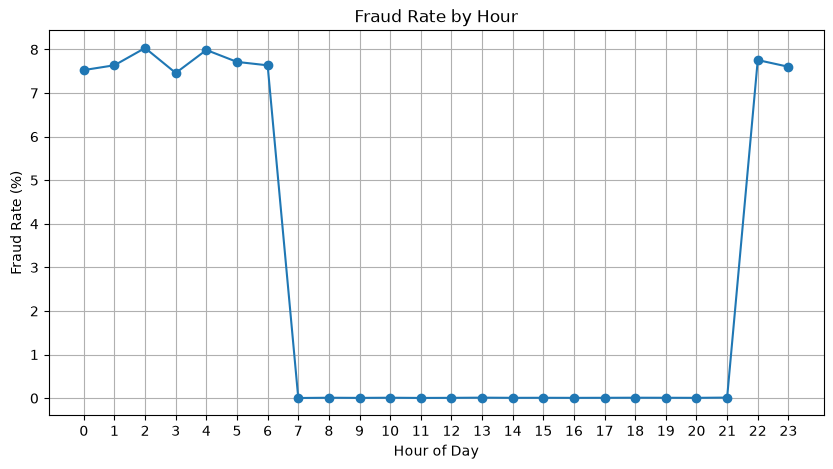

In [23]:
fraud_by_hour["fraud_rate_pct"].plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Fraud Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))
plt.grid(True)
plt.show()

In [27]:
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

fraud_by_day = (
    df.groupby("day_of_week")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
)

fraud_by_day["fraud_rate_pct"] = (
    fraud_by_day["fraud_transactions"]
    / fraud_by_day["total_transactions"] * 100
)

fraud_by_day = fraud_by_day.reindex(day_order)

print(fraud_by_day)

             total_transactions  fraud_transactions  fraud_rate_pct
day_of_week                                                        
Monday                   718409                5799        0.807200
Tuesday                  712714                5552        0.778994
Wednesday                713190                5771        0.809181
Thursday                 711925                5701        0.800787
Friday                   711919                5727        0.804445
Saturday                 711709                5646        0.793302
Sunday                   720134                5804        0.805961


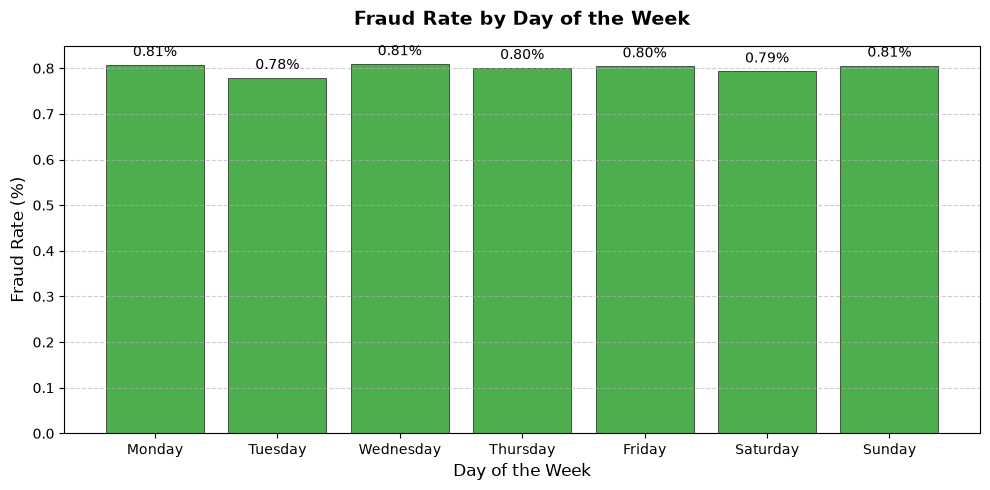

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    fraud_by_day.index,
    fraud_by_day["fraud_rate_pct"],
    color="#2ca02c",
    alpha=0.85,
    edgecolor="black",
    linewidth=0.5,
)
ax.set_title("Fraud Rate by Day of the Week", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Day of the Week", fontsize=12)
ax.set_ylabel("Fraud Rate (%)", fontsize=12)

ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.xticks(rotation=0)  


for bar in bars:
  height = bar.get_height()
  ax.annotate(
      f"{height:.2f}%",
      xy=(bar.get_x() + bar.get_width() / 2, height),
      xytext=(0, 4),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=10,
  )

plt.tight_layout()
plt.show()

In [29]:
fraud_by_month = (
    df.groupby("month")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum"),
        fraud_value_ngn=(
            "amount_ngn",
            lambda x: x[df.loc[x.index, "fraud_flag"] == True].sum()
        )
    )
)

fraud_by_month["fraud_rate_pct"] = (
    fraud_by_month["fraud_transactions"]
    / fraud_by_month["total_transactions"] * 100
)

print(fraud_by_month)

         total_transactions  fraud_transactions  fraud_value_ngn  \
month                                                              
2023-01              212264                1702      106081504.0   
2023-02              192352                1561       87104400.0   
2023-03              212317                1694      104407200.0   
2023-04              205684                1677       93373904.0   
2023-05              211652                1757      121441704.0   
2023-06              204805                1598      100654200.0   
2023-07              213257                1669      107843600.0   
2023-08              211978                1757      102188096.0   
2023-09              205075                1647      114175600.0   
2023-10              212944                1668      111196304.0   
2023-11              205233                1623      116970800.0   
2023-12              213082                1724      125527904.0   
2024-01              212539                1627 

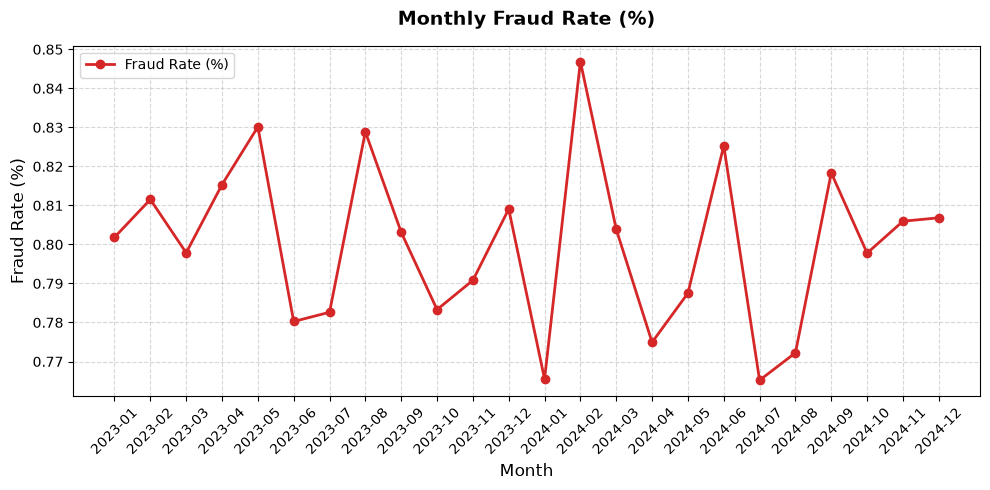

In [45]:
df_monthly = fraud_by_month.sort_index()
months = df_monthly.index.astype(str)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    months,
    df_monthly["fraud_rate_pct"],
    color="#d62728",
    marker="o",
    linewidth=2,
    label="Fraud Rate (%)",
)
ax.set_title("Monthly Fraud Rate (%)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Fraud Rate (%)", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", frameon=True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [31]:
fraud_by_state = (
    df.groupby("location_state")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum"),
        total_transaction_value=("amount_ngn", "sum")
    )
)

fraud_by_state["fraud_rate_pct"] = (
    fraud_by_state["fraud_transactions"]
    / fraud_by_state["total_transactions"] * 100
)

fraud_by_state["fraud_value_ngn"] = (
    df[df["fraud_flag"] == True]
    .groupby("location_state")["amount_ngn"]
    .sum()
)

fraud_by_state["fraud_value_ngn"] = (
    fraud_by_state["fraud_value_ngn"].fillna(0)
)

print(
    fraud_by_state
    .sort_values("fraud_rate_pct", ascending=False)
    .head(10)
)

                total_transactions  fraud_transactions  \
location_state                                           
Bayelsa                       6347                  72   
Gombe                        11756                 116   
Nasarawa                     11413                  99   
Cross River                  45599                 395   
Yobe                         15820                 136   
Borno                        46956                 397   
Kaduna                      159387                1339   
Zamfara                      25685                 214   
Edo                         125496                1043   
Bauchi                       42255                 350   

                total_transaction_value  fraud_rate_pct  fraud_value_ngn  
location_state                                                            
Bayelsa                    4.302871e+08        1.134394        7210200.0  
Gombe                      7.447188e+08        0.986730        8452800.0  
Nas

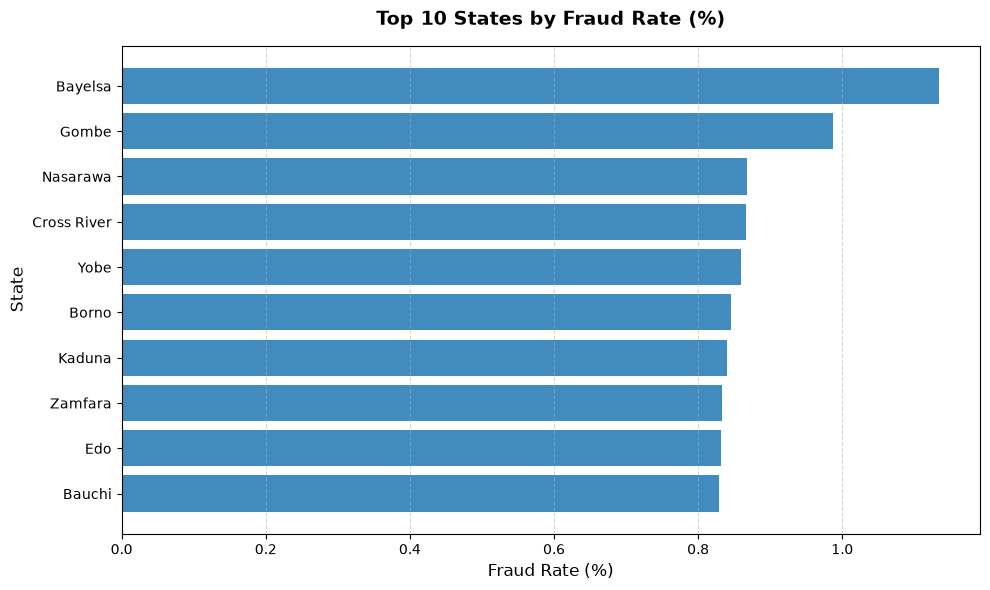

In [47]:
top_states = (
    fraud_by_state.sort_values("fraud_rate_pct", ascending=False)
    .head(10)
    .sort_values(
        "fraud_rate_pct", ascending=True
    ) 
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_states.index, top_states["fraud_rate_pct"], color="#1f77b4", alpha=0.85
)

ax.set_title("Top 10 States by Fraud Rate (%)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Fraud Rate (%)", fontsize=12)
ax.set_ylabel("State", fontsize=12)
ax.grid(axis="x", linestyle="--", alpha=0.5)


plt.tight_layout()
plt.show()

In [33]:
fraud_by_lga = (
    df.groupby(["location_state", "location_lga"])
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
)

fraud_by_lga["fraud_rate_pct"] = (
    fraud_by_lga["fraud_transactions"]
    / fraud_by_lga["total_transactions"] * 100
)

fraud_by_lga = fraud_by_lga[
    fraud_by_lga["total_transactions"] >= 100
]

print(
    fraud_by_lga
    .sort_values("fraud_rate_pct", ascending=False)
    .head(10)
)

                                total_transactions  fraud_transactions  \
location_state location_lga                                              
Bayelsa        Bayelsa LGA                    6347                  72   
Gombe          Gombe LGA                     11756                 116   
Nasarawa       Nasarawa LGA                  11413                  99   
Cross River    Cross River LGA               45599                 395   
Yobe           Yobe LGA                      15820                 136   
Borno          Borno LGA                     46956                 397   
Kaduna         Kaduna LGA                   159387                1339   
Zamfara        Zamfara LGA                   25685                 214   
Edo            Edo LGA                      125496                1043   
Bauchi         Bauchi LGA                    42255                 350   

                                fraud_rate_pct  
location_state location_lga                     
Bayelsa      

         total_transactions  fraud_transactions  total_amount_ngn  \
channel                                                             
agent                 24917                 211      1.538210e+09   
branch               149372                1261      9.952760e+09   
ussd                  75336                 619      4.950228e+09   
pos                 1501370               12059      9.837996e+10   
atm                  999469                8025      6.575228e+10   
web                  500493                4012      3.258224e+10   
mobile              1749043               13813      1.149543e+11   

         fraud_rate_pct  fraud_value_ngn  
channel                                   
agent          0.846811       14029000.0  
branch         0.844201       89091000.0  
ussd           0.821652       28582900.0  
pos            0.803200      793753472.0  
atm            0.802926      550250496.0  
web            0.801610      245441200.0  
mobile         0.789746      93936

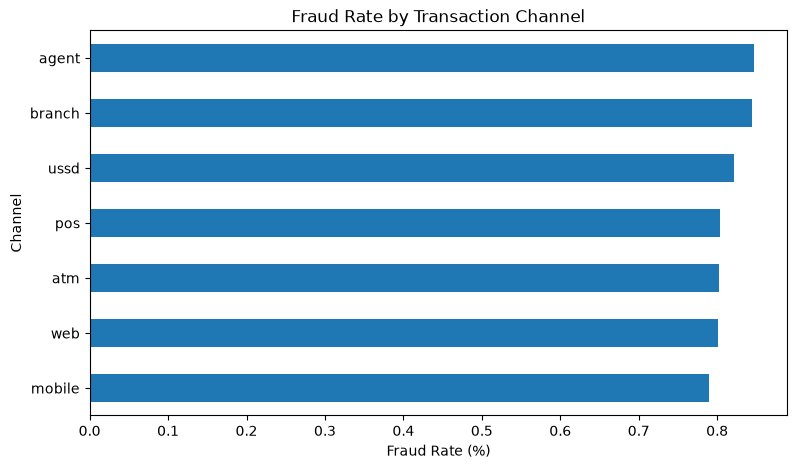

In [34]:
fraud_by_channel = (
    df.groupby("channel")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum"),
        total_amount_ngn=("amount_ngn", "sum")
    )
)

fraud_by_channel["fraud_rate_pct"] = (
    fraud_by_channel["fraud_transactions"]
    / fraud_by_channel["total_transactions"] * 100
)

fraud_by_channel["fraud_value_ngn"] = (
    df[df["fraud_flag"] == True]
    .groupby("channel")["amount_ngn"]
    .sum()
    .reindex(fraud_by_channel.index, fill_value=0)
)

print(fraud_by_channel.sort_values("fraud_rate_pct", ascending=False))

fraud_by_channel["fraud_rate_pct"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Fraud Rate by Transaction Channel")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Channel")
plt.show()

In [35]:
fraud_by_category = (
    df.groupby("merchant_category_code")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
)

fraud_by_category["fraud_rate_pct"] = (
    fraud_by_category["fraud_transactions"]
    / fraud_by_category["total_transactions"] * 100
)

print(
    fraud_by_category
    .sort_values("fraud_rate_pct", ascending=False)
    .head(10)
)

                        total_transactions  fraud_transactions  fraud_rate_pct
merchant_category_code                                                        
5999                                100015                 835        0.834875
4899                                120426                 999        0.829555
5311                                 60208                 496        0.823811
5812                                239530                1963        0.819522
5732                                 80443                 650        0.808026
4900                                160888                1298        0.806772
4814                                400590                3226        0.805312
5411                                300383                2418        0.804972
5541                                200467                1605        0.800631
5499                                 39915                 319        0.799198


In [36]:
fraud_by_type = (
    df.groupby("transaction_type")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
)

fraud_by_type["fraud_rate_pct"] = (
    fraud_by_type["fraud_transactions"]
    / fraud_by_type["total_transactions"] * 100
)

fraud_by_type["fraud_value_ngn"] = (
    df[df["fraud_flag"] == True]
    .groupby("transaction_type")["amount_ngn"]
    .sum()
    .reindex(fraud_by_type.index, fill_value=0)
)

print(fraud_by_type.sort_values("fraud_rate_pct", ascending=False))

                  total_transactions  fraud_transactions  fraud_rate_pct  \
transaction_type                                                           
credit                       1749459               14087         0.80522   
debit                        3250541               25913         0.79719   

                  fraud_value_ngn  
transaction_type                   
credit               9.262502e+08  
debit                1.734263e+09  


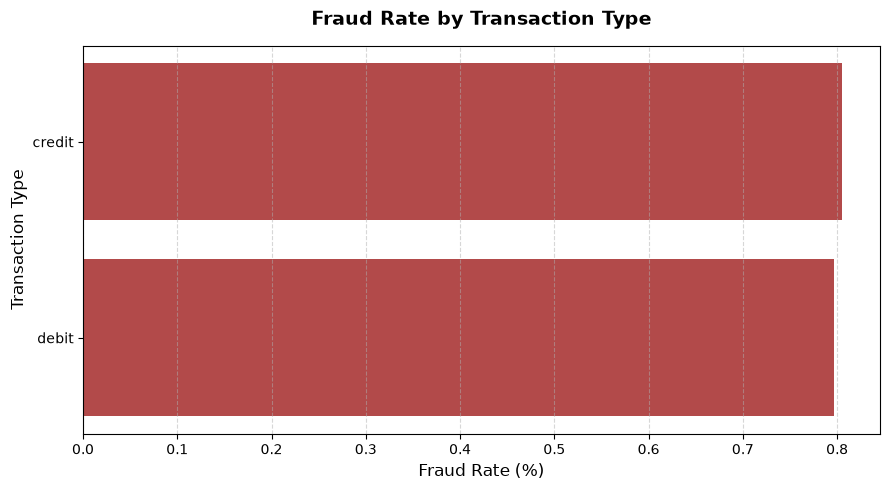

In [53]:
chart_data = fraud_by_type.sort_values("fraud_rate_pct", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    chart_data.index,
    chart_data["fraud_rate_pct"],
    color="brown",
    alpha=0.85,
)


ax.set_title("Fraud Rate by Transaction Type", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Fraud Rate (%)", fontsize=12)
ax.set_ylabel("Transaction Type", fontsize=12)
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

                  total_transactions  fraud_transactions  fraud_rate_pct
amount_group                                                            
₦0–₦1,000                     394079                3148        0.798825
₦1,001–₦5,000                1079908                8709        0.806458
₦5,001–₦10,000                713870                5692        0.797344
₦10,001–₦50,000              1654109               13237        0.800250
₦50,001–₦100,000              499933                3835        0.767103
Above ₦100,000                658101                5379        0.817352


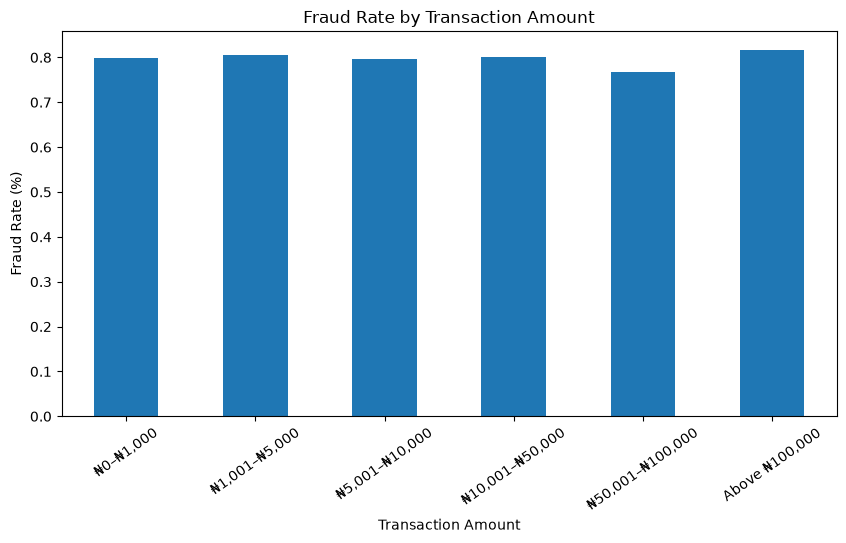

In [39]:
df["amount_group"] = pd.cut(
    df["amount_ngn"],
    bins=[-np.inf, 1000, 5000, 10000, 50000, 100000, np.inf],
    labels=[
        "₦0–₦1,000",
        "₦1,001–₦5,000",
        "₦5,001–₦10,000",
        "₦10,001–₦50,000",
        "₦50,001–₦100,000",
        "Above ₦100,000"
    ]
)

fraud_by_amount = (
    df.groupby("amount_group", observed=False)
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
)

fraud_by_amount["fraud_rate_pct"] = (
    fraud_by_amount["fraud_transactions"]
    / fraud_by_amount["total_transactions"].replace(0, np.nan) * 100
)

print(fraud_by_amount)

fraud_by_amount["fraud_rate_pct"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Fraud Rate by Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=35)
plt.show() 